# Reconstructing Aircraft Traffic Patterns from OpenSky Data
**Final analysis notebook**  
Marwan Elawady · Gasser Elkhodary · Amira Alkafoury

**Research question:** How do observed aircraft activity, spatial concentration, and movement characteristics vary around ATL, ORD, and DFW, and which unusual observations or reporting patterns merit investigation?

**Planned scope:** four Mondays (April 4, 11, 18 and 25, 2022) within 80 km of each airport, with at least 500,000 regional observations.

**Data availability:** OpenSky emptied its public *Weekly 24 Hours of State Vector Data* archive (`states/` folder) on **November 4, 2026**; every 2022 hourly file now returns "not found". The pipeline therefore supports two data modes with the same schema and identical processing:

| `DATA_MODE` | Source | How to get it |
|---|---|---|
| `'live'` (default) | OpenSky live REST API, polled every 10 s around the three airports | Run `collect_opensky_live.py` on a laptop (or section 2c below), put the `states_*.csv` files in `live_data/` |
| `'archive'` | Original hourly `states_YYYY-MM-DD-HH.csv.tar` archives, or `regional_raw.csv.gz` from Progress Check 1 | Local copies only, unless OpenSky restores the archive |

**Run:** put your data files in the `live_data` folder next to this notebook (Colab: `/content/live_data`), then **Run all**. Dates are detected automatically from the data. All findings and the completion status are calculated from the actual inputs; nothing is fabricated to fill missing hours.


In [3]:
# Run only if imports fail, then restart the kernel.
%pip install pandas numpy requests matplotlib pyarrow ipython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Study configuration
All timestamps are UTC. ATL uses America/New_York; ORD and DFW use America/Chicago for local-clock comparisons. Local-clock plots retain the selected UTC-day windows, which contain parts of adjacent local dates.

| Responsibility | Team member |
|---|---|
| Collection, provenance, integration | Marwan Elawady |
| Cleaning, reconstruction, validation | Amira Alkafoury |
| Analysis, visualization, interpretation | Gasser Elkhodary |

**Data mode.** `DATA_MODE='live'` reads every `*states_*.csv` / `.xlsx` file in `LIVE_DIR` and sets `DATES` from the data. `DATA_MODE='archive'` uses the 2022 Mondays and `INPUT_PATHS`.

In archive mode, set `INPUT_PATHS` to a file or a folder. Supported inputs: hourly `states_YYYY-MM-DD-HH.csv.tar`, CSV/CSV.GZ files, and `regional_raw.csv.gz` from Progress Check 1. Prefer original archives; regional exports cannot independently establish that a complete hourly archive was acquired. Do not mix different study datasets under misleading filenames.

In [4]:
from pathlib import Path
from datetime import datetime, timezone
from zoneinfo import ZoneInfo
import hashlib, json, gzip, tarfile, re, sys, shutil, importlib.metadata
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import pyarrow as pa
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import matplotlib.pyplot as plt

VERSION = 'final-2.0'
DATES = ['2022-04-04','2022-04-11','2022-04-18','2022-04-25']
AIRPORTS = {'ATL':(33.6407,-84.4277,'America/New_York'),
            'ORD':(41.9742,-87.9073,'America/Chicago'),
            'DFW':(32.8998,-97.0403,'America/Chicago')}
RADIUS_KM = 80.0
STALE_SECONDS = 60
GAP_SECONDS = 300
SPEED_FLAG_MPS = 350
CHUNK_SIZE = 100_000
TARGET_ROWS = 500_000
BASE = 'https://s3.opensky-network.org/data-samples'
NUMERIC = ['time','lat','lon','velocity','heading','vertrate','baroaltitude','geoaltitude','lastcontact','lastposupdate']
COLUMNS = ['icao24','callsign','onground'] + NUMERIC
KEYS = ['airport_region','icao24','time']


from IPython.display import display, Markdown, Image

# ── Data mode ─────────────────────────────────────────────────────────────
DATA_MODE = 'live'          # 'live' = files from collect_opensky_live.py ; 'archive' = 2022 hourly .csv.tar archives
LIVE_DIR = Path('/content/live_data') if Path('/content').exists() else Path.cwd() / 'live_data'
LIVE_DIR.mkdir(parents=True, exist_ok=True)
COLLECT_MINUTES = 0          # 0 = reproduce the saved run from live_data/; >0 collects new live data first (section 2c; laptop only, not Colab)
ROOT = Path.cwd() / 'aircraft_final'
INPUT_PATHS = [
    Path.cwd() / 'progress_check_project' / 'data' / 'raw',
    # '/home/YOUR_USERNAME/Downloads/states_2022-04-04-00.csv.tar',
    # '/content/states_2022-04-04-00.csv.tar',
    # '/path/to/previous/run/regional_raw.csv.gz',
]
AUTO_DOWNLOAD = False  # Enable only to retry the official archive if it becomes available.
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = ROOT / 'results' / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)
for name in ['data/raw','data/regional','metadata','notebooks','src','tests','reports']:
    (ROOT/name).mkdir(parents=True,exist_ok=True)
print('Results folder:', OUT)


Results folder: c:\Users\gelkhoda\Downloads\aircraft_final\results\20261110T023641574097Z


In [5]:
def stamp(): return datetime.now(timezone.utc).isoformat()


def sha(path):
    with open(path,'rb') as f:
        h=hashlib.sha256()
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()


def dump(path,obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(obj,indent=2,default=lambda x:x.item() if hasattr(x,'item') else str(x)),encoding='utf-8')


def haversine(lat1,lon1,lat2,lon2):
    a,b,c,d=map(np.radians,[lat1,lon1,lat2,lon2])
    q=np.sin((c-a)/2)**2+np.cos(a)*np.cos(c)*np.sin((d-b)/2)**2
    return 6371.0088*2*np.arcsin(np.sqrt(np.clip(q,0,1)))


def discover_local(paths):
    result=[]
    for value in paths:
        p=Path(value).expanduser()
        if p.is_file():result.append(p.resolve())
        elif p.is_dir():
            for pattern in ['*states_*.csv.tar','*states_*.csv.gz','*states_*.csv','regional_raw.csv.gz']:
                result.extend(x.resolve() for x in p.rglob(pattern))
    return sorted(set(result))


In [6]:
dump(OUT/'config.json', {'version':VERSION,'dates':DATES,'airports':AIRPORTS,'radius_km':RADIUS_KM,
     'stale_seconds':STALE_SECONDS,'gap_seconds':GAP_SECONDS,'speed_flag_mps':SPEED_FLAG_MPS,
     'target_rows':TARGET_ROWS,'auto_download':AUTO_DOWNLOAD,'input_paths':[str(p) for p in INPUT_PATHS]})
(ROOT/'requirements.txt').write_text('pandas\nnumpy\nrequests\nmatplotlib\npyarrow\nipython\n')
(ROOT/'.gitignore').write_text('data/\nresults/\n.env\n.ipynb_checkpoints/\n')
(ROOT/'README.md').write_text('# Aircraft Traffic Reconstruction\nRun the final notebook. '
    'Source files and regional partitions stay local. Commit code, reviewed aggregates, methods, and documentation.\n')


169

## 2. Data source and provenance
**Source:** The OpenSky Network, [scientific datasets](https://opensky-network.org/data/scientific). Each source row is a time-stamped state vector, not a flight. Field definitions and units follow the [historical-data documentation](https://openskynetwork.github.io/opensky-api/trino.html).

| Field | Meaning / unit |
|---|---|
| `time`, `lastcontact`, `lastposupdate` | Unix seconds; state, message, and position times |
| `icao24`, `callsign` | Aircraft identifier and broadcast callsign; neither uniquely defines a flight |
| `lat`, `lon` | Position in decimal degrees |
| `velocity`, `vertrate` | Ground and vertical speed in m/s |
| `heading` | Track angle in degrees from north |
| `baroaltitude`, `geoaltitude` | Barometric and geometric altitude in metres |
| `source_id`, `source_member`, `source_row` | File hash prefix, member filename, and one-based row lineage |

Imported file hashes, sizes, dates, and row counts are saved in `source_manifest.json`. URLs for manually supplied canonical filenames are inferred from the original archive convention; they are not evidence that the remote file is currently available. Original archives are preserved. TAR contents are read without extracting arbitrary member paths. Source terms and attribution requirements still apply; review them before redistributing raw data.

Official historical database access is an alternative if your institution’s OpenSky request is approved. Export state vectors with the documented columns, then supply the CSV path. No credentials are stored by this notebook.

In [7]:
def download_missing(root,dates,enabled=False):
    """Read official listing, never assume a missing archive exists; retry only transient failures."""
    if not enabled:return [],[]
    import xml.etree.ElementTree as ET
    session=requests.Session()
    session.mount('https://',HTTPAdapter(max_retries=Retry(total=2,backoff_factor=1,
        status_forcelist=[429,500,502,503,504],allowed_methods=['GET'])))
    folder=Path(root)/'data/raw';folder.mkdir(parents=True,exist_ok=True)
    files=[];errors=[]
    for day in dates:
        try:
            params={'list-type':'2','prefix':f'states/{day}/'};items=[]
            while True:
                response=session.get(BASE,params=params,timeout=(30,90));response.raise_for_status()
                tree=ET.fromstring(response.content);ns={'s':'http://s3.amazonaws.com/doc/2006-03-01/'}
                for obj in tree.findall('s:Contents',ns):
                    key=obj.findtext('s:Key',namespaces=ns)
                    if key.endswith('.csv.tar'):items.append((key,int(obj.findtext('s:Size',namespaces=ns))))
                token=tree.findtext('s:NextContinuationToken',namespaces=ns)
                if not token:break
                params['continuation-token']=token
            if not items:errors.append({'date':day,'error':'No CSV TAR archives in current official listing'});continue
            for key,size in items:
                path=folder/Path(key).name;receipt=path.with_suffix('.receipt.json')
                if path.exists() and receipt.exists():
                    old=json.loads(receipt.read_text())
                    if path.stat().st_size==size and sha(path)==old['sha256']:files.append(path);continue
                    raise ValueError(f'Cached checksum mismatch: {path}')
                if path.exists():files.append(path);continue  # Local import validates content below.
                temp=path.with_suffix('.part')
                try:
                    with session.get(BASE+'/'+key,stream=True,timeout=(30,120)) as r:
                        r.raise_for_status()
                        with temp.open('wb') as f:
                            for b in r.iter_content(1024*1024):
                                if b:f.write(b)
                    if temp.stat().st_size!=size or not tarfile.is_tarfile(temp):raise ValueError('Invalid/incomplete download')
                    temp.replace(path)
                    dump(receipt,{'url':BASE+'/'+key,'retrieved_utc':stamp(),'sha256':sha(path),'bytes':size})
                    files.append(path)
                finally:temp.unlink(missing_ok=True)
        except (requests.RequestException,ValueError,ET.ParseError) as e:errors.append({'date':day,'error':str(e)})
    return files,errors


def iter_frames(path):
    """Never extract TAR member paths to disk. Row numbers exclude the CSV header."""
    def chunks(stream,member):
        offset=0
        for df in pd.read_csv(stream,chunksize=CHUNK_SIZE,dtype={'icao24':'string','callsign':'string'},low_memory=False):
            df.columns=df.columns.str.strip().str.lower()
            yield df,member,offset
            offset+=len(df)
    if str(path).endswith('.tar'):
        with tarfile.open(path,'r:*') as archive:
            for member in archive:
                if not member.isfile() or not member.name.endswith(('.csv','.csv.gz')):continue
                with archive.extractfile(member) as stream:
                    if member.name.endswith('.gz'):
                        with gzip.GzipFile(fileobj=stream) as data:yield from chunks(data,member.name)
                    else:yield from chunks(stream,member.name)
    elif str(path).endswith('.gz'):
        with gzip.open(path,'rb') as f:yield from chunks(f,path.name)
    else:
        with path.open('rb') as f:yield from chunks(f,path.name)


def acquire(files,root,dates=DATES):
    root=Path(root);cache=root/'data/regional';cache.mkdir(parents=True,exist_ok=True)
    manifest=[];failures=[];seen=set()
    config_hash=hashlib.sha256(json.dumps([VERSION,dates,AIRPORTS,RADIUS_KM],sort_keys=True).encode()).hexdigest()[:12]
    for number,path in enumerate(files,1):
        path=Path(path);digest=sha(path)
        if digest in seen:continue
        seen.add(digest);sid=digest[:16];receipt_path=cache/f'{sid}_{config_hash}.json'
        if receipt_path.exists():
            record=json.loads(receipt_path.read_text())
            if all((root/p['path']).exists() and sha(root/p['path'])==p['sha256'] for p in record['partitions']):
                manifest.append(record);print(f'[{number}/{len(files)}] verified regional cache: {path.name}');continue
        parts=[];scanned=0;invalid_position=0;invalid_time=0;outside=0;sample_min=None;sample_max=None
        original_hours=set();members=set();part_counter=0;regions_found=set()
        try:
            for frame,member,offset in iter_frames(path):
                members.add(member)
                missing={'time','icao24','lat','lon'}-set(frame)
                if missing:raise ValueError(f'{path.name}: missing {sorted(missing)}')
                scanned+=len(frame)
                # Retain lineage from an earlier regional export and also record current import row.
                origin_source=frame['source_id'].astype('string') if 'source_id' in frame else pd.Series(sid,index=frame.index,dtype='string')
                origin_member=frame['source_member'].astype('string') if 'source_member' in frame else pd.Series(member,index=frame.index,dtype='string')
                origin_row=pd.to_numeric(frame['source_row'],errors='coerce') if 'source_row' in frame else pd.Series(np.arange(offset+1,offset+len(frame)+1),index=frame.index)
                data=pd.DataFrame(index=frame.index)
                for col in COLUMNS:
                    values=frame[col] if col in frame else pd.Series(pd.NA,index=frame.index)
                    data[col]=pd.to_numeric(values,errors='coerce').astype(float) if col in NUMERIC else values.astype('string')
                data['icao24']=data.icao24.str.strip().str.lower()
                data['source_id']=sid;data['source_member']=member;data['source_row']=np.arange(offset+1,offset+len(data)+1)
                data['origin_source']=origin_source;data['origin_member']=origin_member;data['origin_row']=origin_row.astype(float)
                ts=pd.to_datetime(data.time,unit='s',utc=True,errors='coerce')
                invalid_time+=int(ts.isna().sum());coords=data.lat.between(-90,90)&data.lon.between(-180,180)
                invalid_position+=int((~coords).sum())
                valid_ts=ts.dropna()
                if len(valid_ts):
                    lo=float(data.loc[ts.notna(),'time'].min());hi=float(data.loc[ts.notna(),'time'].max())
                    sample_min=lo if sample_min is None else min(sample_min,lo);sample_max=hi if sample_max is None else max(sample_max,hi)
                    original_hours.update((x.strftime('%Y-%m-%d'),x.hour) for x in valid_ts.dt.floor('h').unique())
                selected=ts.dt.strftime('%Y-%m-%d').isin(dates);outside+=int((~selected&ts.notna()).sum())
                data['day']=ts.dt.strftime('%Y-%m-%d');data['utc_hour']=ts.dt.hour.astype('Int64')
                data=data.loc[coords&selected].copy()
                for airport,(lat,lon,_) in AIRPORTS.items():
                    # Cheap bounding box precedes exact radial filtering.
                    bound=data.lat.between(lat-.8,lat+.8)&data.lon.between(lon-1.2,lon+1.2)
                    near=data.loc[bound].copy()
                    dist=haversine(near.lat,near.lon,lat,lon)
                    near=near.loc[dist<=RADIUS_KM].copy()
                    if near.empty:continue
                    near['airport_region']=airport;near['distance_km']=dist.loc[near.index]
                    regions_found.add(airport)
                    for (day,hour),part in near.groupby(['day','utc_hour']):
                        rel=Path('data/regional')/f'{sid}_{config_hash}_{part_counter:05d}.parquet';part_counter+=1
                        part.to_parquet(root/rel,index=False)
                        parts.append({'path':str(rel),'day':day,'hour':int(hour),'region':airport,'rows':len(part),'sha256':sha(root/rel)})
            if scanned==0:raise ValueError('No readable CSV observations')
            match=re.fullmatch(r'states_(\d{4}-\d{2}-\d{2})-(\d{2})\.csv\.tar',path.name)
            # A complete scan of a canonical hourly archive confirms source acquisition, not receiver coverage.
            verified_hour=None
            if match and original_hours=={(match[1],int(match[2]))}:
                verified_hour=[match[1],int(match[2])]
            source_url=BASE+f'/states/{match[1]}/{match[2]}/{path.name}' if match else None
            record={'source_id':sid,'file_name':path.name,'source_path':str(path.resolve()),'url':source_url,
                    'sha256':digest,'bytes':path.stat().st_size,'imported_utc':stamp(),
                    'scanned_rows':scanned,'invalid_position_rows':invalid_position,'invalid_time_rows':invalid_time,
                    'outside_requested_dates':outside,'regional_rows':sum(x['rows'] for x in parts),
                    'verified_archive_hour':verified_hour,'observed_hours':sorted(original_hours),
                    'min_time':sample_min,'max_time':sample_max,'members':sorted(members),'partitions':parts}
            dump(receipt_path,record);manifest.append(record)
            print(f'[{number}/{len(files)}] {path.name}: {scanned:,} scanned; {record["regional_rows"]:,} regional')
        except Exception as e:
            failures.append({'file':str(path),'error':str(e)})
            # No success receipt is written for partial extraction; incomplete parts are ignored.
    return manifest,failures


### 2b. Archive mode only: retry the 2022 hourly archives
Skipped in live mode. Tries the original path `states/YYYY-MM-DD/HH/` and the dot-prefixed layout on both OpenSky hosts. As of November 4, 2026 the folders are empty placeholders, so expect `MISSING` unless OpenSky restores them.


In [8]:
# ── 2b. Fetch OpenSky hourly archives (tries every known URL layout) ──────────
# Run on your own PC or Colab (needs internet). Files land in aircraft_final/data/raw
# and are picked up automatically. Already-downloaded files are skipped.
FETCH = DATA_MODE == 'archive'   # archive emptied on 2026-11-04; kept in case OpenSky restores it
FETCH_HOURS = [13, 14, 15, 16]   # UTC hours per date. ~130-250 MB each. Use list(range(24)) for full days.
RAW_DIR = ROOT / 'data' / 'raw'; RAW_DIR.mkdir(parents=True, exist_ok=True)
HOSTS = ['https://s3.opensky-network.org/data-samples', 'https://data-samples.s3.amazonaws.com']

def _candidates(day, hour):
    name = f'states_{day}-{hour:02d}.csv.tar'
    for host in HOSTS:
        for folder in (day, '.' + day):          # newer bucket layout prefixes the date with a dot
            yield f'{host}/states/{folder}/{hour:02d}/{name}', name

def list_available_dates(host=HOSTS[0], year='2022'):
    """Show which date folders the bucket currently has, so you can pick other Mondays if needed."""
    import xml.etree.ElementTree as ET
    ns = {'s': 'http://s3.amazonaws.com/doc/2006-03-01/'}; found = []
    for prefix in (f'states/{year}', f'states/.{year}'):
        params = {'list-type': '2', 'prefix': prefix, 'delimiter': '/'}
        while True:
            r = requests.get(host, params=params, timeout=(20, 60)); r.raise_for_status()
            tree = ET.fromstring(r.content)
            found += [p.findtext('s:Prefix', namespaces=ns) for p in tree.findall('s:CommonPrefixes', ns)]
            token = tree.findtext('s:NextContinuationToken', namespaces=ns)
            if not token: break
            params['continuation-token'] = token
    return sorted(found)

def fetch_archives(dates, hours):
    s = requests.Session()
    s.mount('https://', HTTPAdapter(max_retries=Retry(total=3, backoff_factor=2,
            status_forcelist=[429, 500, 502, 503, 504], allowed_methods=['GET', 'HEAD'])))
    got, log = [], []
    for day in dates:
        for hour in hours:
            target = RAW_DIR / f'states_{day}-{hour:02d}.csv.tar'
            if target.exists() and tarfile.is_tarfile(target):
                got.append(target); log.append({'file': target.name, 'status': 'cached'}); continue
            ok = False
            for url, name in _candidates(day, hour):
                try:
                    with s.get(url, stream=True, timeout=(20, 300)) as r:
                        if r.status_code != 200: continue
                        part = target.with_suffix('.part')
                        with part.open('wb') as f:
                            for b in r.iter_content(1 << 20): f.write(b)
                    if tarfile.is_tarfile(part):
                        part.replace(target); ok = True
                        dump(target.with_suffix('.receipt.json'), {'url': url, 'retrieved_utc': stamp(),
                             'sha256': sha(target), 'bytes': target.stat().st_size})
                        got.append(target); log.append({'file': name, 'status': 'downloaded', 'url': url})
                        print(f'OK  {name}  {target.stat().st_size/1e6:,.0f} MB  ({url})'); break
                    part.unlink(missing_ok=True)
                except requests.RequestException as e:
                    print(f'..  {url}: {type(e).__name__}')
            if not ok:
                log.append({'file': target.name, 'status': 'not found at any URL'}); print(f'MISSING {target.name}')
    return got, log

if FETCH:
    fetched, fetch_log = fetch_archives(DATES, FETCH_HOURS)
    display(pd.DataFrame(fetch_log))
    if not fetched:
        print('Nothing downloaded. Date folders the bucket currently lists for 2022:')
        try: print(list_available_dates())
        except Exception as e: print('Listing failed:', e)
    INPUT_PATHS = list(INPUT_PATHS) + [RAW_DIR]


### 2c. Live mode: collect and prepare inputs
Live data comes from the OpenSky REST API (`/api/states/all`, one bounding box per airport, polled every 10 s). Fields are renamed to the archive schema: `time_position` → `lastposupdate`, `last_contact` → `lastcontact`, `true_track` → `heading`. Each poll gives one state per aircraft, the same 10-second sampling as the weekly archive. Collection runs on a laptop because OpenSky blocks many cloud IP ranges. Anonymous users have a small daily quota; an OpenSky API client raises it.


In [9]:
# ── 2c. Live mode: (optional) collect, then prepare inputs and dates ───────
import csv, math, time

API = 'https://opensky-network.org/api/states/all'
TOKEN_URL = 'https://auth.opensky-network.org/auth/realms/opensky-network/protocol/openid-connect/token'
COLS = ['time','icao24','lat','lon','velocity','heading','vertrate','callsign','onground','alert','spi',
        'squawk','baroaltitude','geoaltitude','lastposupdate','lastcontact']

def bbox(lat, lon, km=RADIUS_KM + 2):
    dlat = km / 111.195; dlon = km / (111.195 * math.cos(math.radians(lat)))
    return dict(lamin=lat - dlat, lamax=lat + dlat, lomin=lon - dlon, lomax=lon + dlon)

def to_rows(payload):
    """Map the REST 'states' array to the historical archive's column names."""
    t = payload.get('time'); rows = []
    for s in payload.get('states') or []:
        # REST order: icao24, callsign, origin_country, time_position, last_contact, lon, lat,
        # baro_altitude, on_ground, velocity, true_track, vertical_rate, sensors, geo_altitude, squawk, spi, ...
        if s[5] is None or s[6] is None: continue
        rows.append({'time': t, 'icao24': s[0], 'lat': s[6], 'lon': s[5], 'velocity': s[9], 'heading': s[10],
                     'vertrate': s[11], 'callsign': (s[1] or '').strip(), 'onground': s[8], 'alert': '',
                     'spi': s[15], 'squawk': s[14], 'baroaltitude': s[7], 'geoaltitude': s[13],
                     'lastposupdate': s[3], 'lastcontact': s[4]})
    return rows

class Auth:
    def __init__(self, cid, secret): self.cid, self.secret, self.token, self.exp = cid, secret, None, 0
    def headers(self):
        if not self.cid: return {}
        if time.time() > self.exp - 60:
            r = requests.post(TOKEN_URL, data={'grant_type': 'client_credentials', 'client_id': self.cid,
                              'client_secret': self.secret}, timeout=30); r.raise_for_status()
            j = r.json(); self.token = j['access_token']; self.exp = time.time() + j.get('expires_in', 1800)
        return {'Authorization': f'Bearer {self.token}'}


def collect_live(minutes, out_dir, interval=10, client_id=None, client_secret=None):
    """Poll the OpenSky REST API around each airport and append hourly CSVs (archive column names)."""
    auth=Auth(client_id,client_secret); boxes={k:bbox(v[0],v[1]) for k,v in AIRPORTS.items()}
    end=time.time()+minutes*60; total=0
    while time.time()<end:
        start=time.time()
        for name,box in boxes.items():
            try:r=requests.get(API,params=box,headers=auth.headers(),timeout=30)
            except requests.RequestException as e:print(name,'network error',type(e).__name__);continue
            if r.status_code==429:print('Daily API quota reached; stopping.');return total
            if r.status_code!=200:print(name,'HTTP',r.status_code);continue
            rows=to_rows(r.json())
            if not rows:continue
            ts=datetime.fromtimestamp(rows[0]['time'],timezone.utc)
            f=Path(out_dir)/f'states_{ts:%Y-%m-%d-%H}.csv';new=not f.exists()
            with f.open('a',newline='') as fh:
                w=csv.DictWriter(fh,fieldnames=COLS)
                if new:w.writeheader()
                w.writerows(rows)
            total+=len(rows)
        print(f'\r{total:,} rows collected',end='')
        time.sleep(max(0,interval-(time.time()-start)))
    return total

if DATA_MODE == 'live':
    if COLLECT_MINUTES > 0:
        collect_live(COLLECT_MINUTES, LIVE_DIR)
    # Excel workbooks -> hourly CSVs (Excel can corrupt hex IDs, so originals are preferred).
    for x in list(LIVE_DIR.glob('*.xlsx')):
        df = pd.read_excel(x, dtype={'icao24': str, 'callsign': str})
        df.columns = df.columns.str.strip().str.lower()
        t = pd.to_datetime(pd.to_numeric(df['time']), unit='s', utc=True)
        for hour, part in df.groupby(t.dt.strftime('%Y-%m-%d-%H')):
            target = LIVE_DIR / f'states_{hour}.csv'
            if not target.exists(): part.to_csv(target, index=False)
    live_files = sorted(p for p in LIVE_DIR.rglob('*states_*.csv'))
    if not live_files:
        raise FileNotFoundError(f'No *states_*.csv files in {LIVE_DIR}. Upload the files from collect_opensky_live.py '
                                f'into this folder (or set COLLECT_MINUTES > 0 on a laptop) and run again.')
    times = pd.concat([pd.read_csv(f, usecols=['time']) for f in live_files])['time']
    times = pd.to_datetime(pd.to_numeric(times, errors='coerce'), unit='s', utc=True).dropna()
    DATES = sorted(times.dt.strftime('%Y-%m-%d').unique())
    INPUT_PATHS = [LIVE_DIR]
    print(f'Live data: {len(live_files)} files, {len(times):,} rows, {times.min()} to {times.max()} UTC')
    print('DATES =', DATES)
dump(OUT/'config.json', {'version':VERSION,'data_mode':DATA_MODE,'dates':DATES,'airports':AIRPORTS,'radius_km':RADIUS_KM,
     'stale_seconds':STALE_SECONDS,'gap_seconds':GAP_SECONDS,'speed_flag_mps':SPEED_FLAG_MPS,
     'target_rows':TARGET_ROWS,'input_paths':[str(p) for p in INPUT_PATHS]})


25,091 rows collectedLive data: 1 files, 25,091 rows, 2026-11-10 02:37:40+00:00 to 2026-11-10 02:52:34+00:00 UTC
DATES = ['2026-11-10']


In [10]:
local_files = discover_local(INPUT_PATHS)
downloaded, access_errors = download_missing(ROOT,DATES,AUTO_DOWNLOAD)
input_files = sorted(set(local_files + [Path(p).resolve() for p in downloaded]))
manifest, import_errors = acquire(input_files,ROOT,DATES)
failures = access_errors + import_errors
dump(OUT/'source_manifest.json',manifest)
dump(OUT/'input_failures.json',failures)
if manifest:
    display(pd.DataFrame([{k:v for k,v in s.items() if k in
        ['file_name','bytes','scanned_rows','regional_rows','sha256','verified_archive_hour']} for s in manifest]))
else:
    display(Markdown('**Source data required.** Set `INPUT_PATHS` to downloaded OpenSky archives or '
                     'the previous `regional_raw.csv.gz` export and run again. No empirical findings will be generated without data.'))
if failures:display(pd.DataFrame(failures))


[1/1] states_2026-11-10-02.csv: 25,091 scanned; 23,466 regional


,file_name,sha256,bytes,scanned_rows,regional_rows,verified_archive_hour
0,states_2026-11-10-02.csv,9253df4f00cd87ba21b3082028189a595ba5f4dda34230...,2678566,25091,23466,None


## 3. Cleaning and track reconstruction
The pipeline selects valid positions within the airport radii and the requested dates, then processes one region-day at a time. It preserves missing optional measurements. Duplicate `(region, aircraft, time)` keys keep the newest contact timestamp, with source/row order breaking ties; conflicting positions are counted.

States are excluded when a known message/position age exceeds **60 seconds**, or an update time lies in the future. Unknown freshness timestamps remain but are reported. Each aircraft’s chronological observations within a region-day are split after gaps over **300 seconds**. Tracks can cross hourly file boundaries, but not the unobserved week between dates. These are candidate segments; they do not prove complete flights, origins, destinations, or route intent.

High reported speeds, impossible position timing, and position-derived speeds above **350 m/s** are review flags. Position-derived speed uses position-update intervals to reduce artifacts from repeated stale locations. Negative speed is flagged; it and speeds above the review threshold are excluded from the speed summaries, but observations remain available for review.

In [11]:
def freshness(df,seconds):
    ages=pd.concat([df.time-df.lastcontact,df.time-df.lastposupdate],axis=1)
    return ~((ages>seconds).any(axis=1)|(ages<0).any(axis=1))


def deduplicate(df):
    valid=df.icao24.str.fullmatch('[0-9a-f]{6}',na=False)&np.isfinite(df.time)
    core=df.loc[valid].copy()
    core=core.sort_values(KEYS+['lastcontact','source_id','source_row'],kind='stable',na_position='first')
    conflicted=core.groupby(KEYS,observed=True).agg(nlat=('lat','nunique'),nlon=('lon','nunique'))
    conflicts=int(((conflicted.nlat>1)|(conflicted.nlon>1)).sum())
    unique=core.drop_duplicates(KEYS,keep='last').copy()
    quality={'regional_input':len(df),'invalid_core_removed':int((~valid).sum()),
             'duplicate_removed':len(core)-len(unique),'conflicting_duplicate_keys':conflicts}
    return unique,quality


def segment(df,gap=GAP_SECONDS,speed=SPEED_FLAG_MPS):
    df=df.sort_values(KEYS).copy()
    # Treat days as distinct observation windows; tracks may cross hour boundaries within a day.
    groups=['airport_region','day','icao24']
    delta=df.groupby(groups,observed=True).time.diff()
    start=delta.isna()|delta.gt(gap)
    number=start.groupby([df[x] for x in groups],observed=True).cumsum().astype(int)
    df['track_id']=df.airport_region+'_'+df.day+'_'+df.icao24+'_'+number.astype(str)
    g=df.groupby('track_id',observed=True)
    df['gap_s']=g.time.diff()
    df['step_km']=haversine(g.lat.shift(),g.lon.shift(),df.lat,df.lon)
    # Position update timestamps avoid overstating velocity when state vectors repeat an old position.
    df['position_dt']=g.lastposupdate.diff()
    df['implied_speed_mps']=df.step_km*1000/df.position_dt.where(df.position_dt>0)
    df['invalid_reported_speed']=df.velocity.lt(0)
    df['speed_flag']=df.velocity.gt(speed)
    df['jump_flag']=df.implied_speed_mps.gt(speed)
    df['position_time_conflict']=df.step_km.gt(.1)&df.position_dt.le(0)
    df['timestamp_utc']=pd.to_datetime(df.time,unit='s',utc=True)
    return df


def process(manifest,root,out):
    root=Path(root);out=Path(out);out.mkdir(parents=True,exist_ok=True)
    partitions=[p for source in manifest for p in source['partitions']]
    groups=sorted({(p['day'],p['region']) for p in partitions})
    quality=[];sensitivity=[];hourly=[];daily=[];cells=[];tracks_summary=[];paths=[];audits=[];gaps=[];anomalies=[]
    tests=[];missingness=[];speed_sensitivity=[]
    for day,region in groups:
        selected=[p for p in partitions if (p['day'],p['region'])==(day,region)]
        raw=pd.concat([pd.read_parquet(root/p['path']) for p in selected],ignore_index=True)
        unique,q=deduplicate(raw)
        clean=unique.loc[freshness(unique,STALE_SECONDS)].copy()
        q.update(day=day,region=region,stale_or_future_removed=len(unique)-len(clean),clean_rows=len(clean),
                 unknown_freshness_retained=int(clean[['lastcontact','lastposupdate']].isna().any(axis=1).sum()))
        quality.append(q)
        for col in NUMERIC+['callsign']:
            missingness.append({'day':day,'region':region,'field':col,'missing':int(raw[col].isna().sum()),'total':len(raw)})
        for stale in [15,60,120]:
            subset=unique.loc[freshness(unique,stale)].copy()
            region_counts=len(subset)
            for gap in [120,300,600]:
                t=segment(subset,gap)
                lengths=t.groupby('track_id',observed=True).size()
                sensitivity.append({'day':day,'region':region,'stale_seconds':stale,'gap_seconds':gap,
                                    'rows':region_counts,'segments':len(lengths),'multi_point_segments':int((lengths>=2).sum())})
        if clean.empty:continue
        t=segment(clean)
        name=f'{day}_{region}';track_path=out/f'tracks_{name}.parquet';t.to_parquet(track_path,index=False)
        paths.append(str(track_path))
        summary=t.groupby('track_id',observed=True).agg(region=('airport_region','first'),day=('day','first'),
            aircraft=('icao24','first'),rows=('time','size'),start=('time','min'),end=('time','max'),
            path_km=('step_km','sum'),max_gap_s=('gap_s','max'),speed_flags=('speed_flag','sum'),jump_flags=('jump_flag','sum'))
        summary['duration_min']=(summary.end-summary.start)/60
        summary['candidate_id']=[hashlib.sha256(x.encode()).hexdigest()[:12] for x in summary.index]
        summary.to_parquet(out/f'segments_{name}.parquet')
        tracks_summary.append(summary.reset_index())
        # Observed reporting gaps are based on the cleaned record stream before segmentation.
        gd=clean.sort_values(KEYS).groupby('icao24',observed=True).time.diff().dropna()
        gaps.append({'day':day,'region':region,'intervals':len(gd),'median_gap_s':gd.median(),
                     'p95_gap_s':gd.quantile(.95),'gaps_over_300s':int(gd.gt(300).sum())})
        for hour,h in t.groupby('utc_hour'):
            valid_speed=h.velocity.where(h.velocity.between(0,SPEED_FLAG_MPS))
            bins=pd.to_datetime(h.time,unit='s',utc=True).dt.floor('min').nunique()
            hourly.append({'day':day,'region':region,'utc_hour':int(hour),'rows':len(h),
                'aircraft':h.icao24.nunique(),'observed_minutes':bins,'speed_median_mps':valid_speed.median(),
                'altitude_median_m':h.baroaltitude.median(),'flagged_rows':int((h.speed_flag|h.jump_flag|h.position_time_conflict).sum())})
        daily.append({'day':day,'region':region,'rows':len(t),'aircraft':t.icao24.nunique(),
             'candidate_segments':len(summary),'multi_point_segments':int(summary.rows.ge(2).sum()),
             'speed_median_mps':t.velocity.where(t.velocity.between(0,SPEED_FLAG_MPS)).median(),
             'altitude_median_m':t.baroaltitude.median()})
        lat0,lon0,_=AIRPORTS[region]
        # Local equirectangular grid is approximate; 2 km bins within an 80 km radius.
        x=(t.lon-lon0)*111.195*np.cos(np.radians(lat0));y=(t.lat-lat0)*111.195
        gr=t.assign(gx=np.floor(x/2).astype(int),gy=np.floor(y/2).astype(int)).groupby(['gx','gy']).agg(
            observations=('time','size'),aircraft=('icao24','nunique'))
        gr=gr.reset_index();gr['day']=day;gr['region']=region;cells.append(gr)
        flag=t.speed_flag|t.jump_flag|t.position_time_conflict|t.invalid_reported_speed
        if flag.any():
            examples=t.loc[flag,['track_id','time','lat','lon','velocity','implied_speed_mps','speed_flag','jump_flag','position_time_conflict','invalid_reported_speed','source_id','source_row']].copy()
            examples['region']=region;examples['day']=day;anomalies.append(examples)
        for threshold in [250,350,450]:
            speed_sensitivity.append({'day':day,'region':region,'threshold_mps':threshold,
                'reported_speed_flags':int(t.velocity.gt(threshold).sum()),'position_jump_flags':int(t.implied_speed_mps.gt(threshold).sum())})
        # Audit a short, middle-length, and long multi-point segment for every region-day.
        candidates=summary[summary.rows>=2].sort_values('rows')
        choices=[] if candidates.empty else list(dict.fromkeys([candidates.index[0],candidates.index[len(candidates)//2],candidates.index[-1]]))
        for tid in choices:
            sample=t[t.track_id==tid].iloc[np.unique(np.linspace(0,len(t[t.track_id==tid])-1,min(5,len(t[t.track_id==tid]))).astype(int))]
            lineage=['source_id','source_member','source_row']
            matched=sample.merge(raw[lineage+['time','lat','lon']],on=lineage,how='left',suffixes=('','_raw'),validate='one_to_one')
            ok=all(np.allclose(matched[c],matched[c+'_raw'],equal_nan=True) for c in ['time','lat','lon'])
            audits.append({'day':day,'region':region,'candidate_id':hashlib.sha256(tid.encode()).hexdigest()[:12],
                'sampled_rows':len(sample),'lineage_match':ok,'ordered':bool(t[t.track_id==tid].time.diff().dropna().ge(0).all()),
                'within_gap_threshold':bool(t[t.track_id==tid].gap_s.dropna().le(GAP_SECONDS).all())})
        accounting=q['regional_input']==q['invalid_core_removed']+q['duplicate_removed']+q['stale_or_future_removed']+q['clean_rows']
        checks={'row_accounting':accounting,'deduplicated':not t.duplicated(KEYS).any(),
            'track_ordering':t.groupby('track_id').time.diff().dropna().ge(0).all(),
            'track_gap_limit':t.gap_s.dropna().le(GAP_SECONDS).all(),'region_bound':t.distance_km.le(RADIUS_KM+1e-6).all(),
            'segment_accounting':int(summary.rows.sum())==len(t)}
        tests.extend({'day':day,'region':region,'check':k,'passed':bool(v)} for k,v in checks.items())
        print(f'{day} {region}: {len(raw):,} regional → {len(t):,} cleaned; {len(summary):,} candidate segments')
    def table(rows):return pd.DataFrame(rows)
    result={'quality':table(quality),'sensitivity':table(sensitivity),'hourly':table(hourly),'daily':table(daily),
            'grid':pd.concat(cells,ignore_index=True) if cells else pd.DataFrame(),
            'segments':pd.concat(tracks_summary,ignore_index=True) if tracks_summary else pd.DataFrame(),
            'audits':table(audits),'validation':table(tests),'missingness':table(missingness),'gaps':table(gaps),
            'flags':pd.concat(anomalies,ignore_index=True) if anomalies else pd.DataFrame(),
            'speed_sensitivity':table(speed_sensitivity),'track_paths':paths}
    for k,v in result.items():
        if isinstance(v,pd.DataFrame):v.to_csv(out/f'{k}.csv',index=False)
    return result


In [12]:
results = process(manifest,ROOT,OUT)
if not results['quality'].empty:
    display(results['quality'])
    missing = results['missingness'].groupby('field')[['missing','total']].sum()
    missing['missing_percent']=100*missing['missing']/missing['total']
    display(missing.round(2))
    segment_preview=results['segments'][['candidate_id','region','day','rows','duration_min','path_km']].head(12)
    display(segment_preview)
else:
    print('Cleaning and reconstruction await source data.')


2026-11-10 ATL: 7,357 regional → 6,366 cleaned; 127 candidate segments
2026-11-10 DFW: 8,823 regional → 7,537 cleaned; 153 candidate segments
2026-11-10 ORD: 7,286 regional → 5,701 cleaned; 160 candidate segments


,regional_input,invalid_core_removed,duplicate_removed,conflicting_duplicate_keys,day,region,stale_or_future_removed,clean_rows,unknown_freshness_retained
0,7357,0,0,0,2026-11-10,ATL,991,6366,0
1,8823,0,0,0,2026-11-10,DFW,1286,7537,0
2,7286,0,0,0,2026-11-10,ORD,1585,5701,0


,missing,total,missing_percent
field,,,
baroaltitude,8851,23466,37.72
callsign,765,23466,3.26
geoaltitude,8946,23466,38.12
heading,0,23466,0.00
lastcontact,0,23466,0.00
lastposupdate,0,23466,0.00
lat,0,23466,0.00
lon,0,23466,0.00
time,0,23466,0.00


,candidate_id,region,day,rows,duration_min,path_km
0,13aba03f3f76,ATL,2026-11-10,27,4.316667,57.359079
1,f7937395d0ee,ATL,2026-11-10,29,7.483333,0.295334
2,48136ab7e0b7,ATL,2026-11-10,51,8.333333,2.896557
3,d7c35c969ebc,ATL,2026-11-10,46,7.483333,63.922446
4,4b755351f8e0,ATL,2026-11-10,54,9.300000,12.372205
5,806c845c9ec5,ATL,2026-11-10,75,12.416667,21.144520
6,a7e4407a85ea,ATL,2026-11-10,86,14.333333,49.580429
7,893e2baa63e3,ATL,2026-11-10,90,14.900000,0.000000
8,0182381962f5,ATL,2026-11-10,20,3.150000,0.094423
9,e835c388908d,ATL,2026-11-10,90,14.900000,52.485074


## 4. Coverage and comparison design
A fully scanned canonical hourly archive establishes acquisition of that source hour, not complete receiver coverage. Imported regional subsets can show observed hours but cannot prove source completeness. Unknown hours remain missing; only a fully processed source hour with no retained regional rows receives zero.

Observation counts, distinct aircraft per hour, and counts of candidate segments answer different questions. Aircraft can recur across hours and days; summing daily unique identifiers gives **aircraft-days**. The strongest four-day comparison uses UTC hour-of-day windows acquired on all four dates and in all three regions. Coverage is not statistically corrected: observed-minute counts are diagnostics, not proof of complete detection.

In [13]:
def coverage(manifest,results,dates=DATES):
    acquired={tuple(s['verified_archive_hour']) for s in manifest if s['verified_archive_hour']}
    index=pd.MultiIndex.from_product([dates,AIRPORTS,range(24)],names=['day','region','utc_hour'])
    frame=index.to_frame(index=False)
    frame['source_archive_verified']=[(d,h) in acquired for d,h in zip(frame.day,frame.utc_hour)]
    hourly=results['hourly']
    if not hourly.empty:frame=frame.merge(hourly,on=['day','region','utc_hour'],how='left',validate='one_to_one')
    else:
        for col in ['rows','aircraft','observed_minutes','speed_median_mps','altitude_median_m','flagged_rows']:frame[col]=np.nan
    # Zero is justified only for a fully processed canonical archive. Unknown source hours stay NaN.
    for col in ['rows','aircraft','observed_minutes','flagged_rows']:
        frame.loc[frame.source_archive_verified & frame[col].isna(),col]=0
    frame['has_observations']=frame.rows.fillna(0).gt(0)
    # Live polling has no canonical archive; an hour counts as acquired when observations exist in it.
    frame['acquired']=frame.source_archive_verified|(frame.has_observations if DATA_MODE=='live' else False)
    frame['utc_start']=pd.to_datetime(frame.day,utc=True)+pd.to_timedelta(frame.utc_hour,unit='h')
    frame['local_hour']=[ts.tz_convert(AIRPORTS[r][2]).hour for ts,r in zip(frame.utc_start,frame.region)]
    frame['local_date']=[ts.tz_convert(AIRPORTS[r][2]).strftime('%Y-%m-%d') for ts,r in zip(frame.utc_start,frame.region)]
    return frame


def summarize(manifest,result,cov,failures):
    quality=result['quality'];clean_count=int(quality.clean_rows.sum()) if not quality.empty else 0
    verified=len({tuple(s['verified_archive_hour']) for s in manifest if s['verified_archive_hour']})
    regional=sum(s['regional_rows'] for s in manifest)
    ok=(not result['validation'].empty and result['validation'].passed.all()
        and not result['audits'].empty and result['audits'][['lineage_match','ordered','within_gap_threshold']].all().all())
    full=verified==len(DATES)*24
    if DATA_MODE=='live':
        label=('BLOCKED — SOURCE DATA REQUIRED' if not regional else
               f'LIVE-DATA RUN — {"VALIDATED" if ok and not failures else "CHECK FAILURES"} '
               f'({len(DATES)} day(s), {int(cov.acquired.sum()//len(AIRPORTS))} UTC hour(s) with data)')
    else:
        label='COMPLETE FOR PLANNED SCOPE' if full and regional>=TARGET_ROWS and clean_count>=TARGET_ROWS and ok and not failures else (
            'PARTIAL DATA — FINAL-SCOPE REQUIREMENTS NOT MET' if regional else 'BLOCKED — SOURCE DATA REQUIRED')
    return {'status':label,'sources':len(manifest),'source_rows_scanned':sum(s['scanned_rows'] for s in manifest),
        'regional_rows_before_cleaning':regional,'clean_rows':clean_count,'verified_archive_hours':verified,
        'planned_archive_hours':len(DATES)*24,'data_mode':DATA_MODE,'hours_with_data':int(cov.acquired.sum()//len(AIRPORTS)),'regional_500k_target_met':regional>=TARGET_ROWS,
        'clean_500k_target_met':clean_count>=TARGET_ROWS,'full_four_day_acquisition':full,
        'validation_passed':bool(ok),'failed_inputs':len(failures),'candidate_segments':len(result['segments'])}


In [14]:
coverage_table = coverage(manifest,results,DATES)
status = summarize(manifest,results,coverage_table,failures)
coverage_table.to_csv(OUT/'coverage.csv',index=False)
display(pd.Series(status,name='value').to_frame())
display(coverage_table.groupby(['day','region']).agg(
    verified_source_hours=('source_archive_verified','sum'),
    hours_with_observations=('has_observations','sum')))


,value
status,"LIVE-DATA RUN — VALIDATED (1 day(s), 1 UTC hou..."
sources,1
source_rows_scanned,25091
regional_rows_before_cleaning,23466
clean_rows,19604
verified_archive_hours,0
planned_archive_hours,24
data_mode,live
hours_with_data,1
regional_500k_target_met,False


verified_source_hours  hours_with_observations
day        region                                                
2026-11-10 ATL                         0                        1
           DFW                         0                        1
           ORD                         0                        1

## 5. Traffic patterns, spatial concentration, and movement
The figures show available-data totals, day/hour coverage, UTC and local-clock profiles, approximate 2 km spatial bins, movement profiles, threshold sensitivity, and representative candidate tracks. Spatial concentration is based on observation density; it can reflect aircraft dwell time and sampling as well as frequently used corridors. Small route plots use anonymous candidate labels.

Hourly count deviations use each day’s count relative to the median of the other three Mondays for the same region/hour. Ratios below 0.5 or above 1.5 are exploratory candidates only; all four source windows must be present. A robust score is reported only if the reference median absolute deviation is nonzero. This small reference set does not justify a confirmed-disruption claim.

In [15]:
def analyze(result,cov,out):
    out=Path(out);tables={};figures=[];findings=[]
    if result['hourly'].empty:
        return tables,figures,['No usable source observations were available. Empirical findings cannot be computed.']
    cov.to_csv(out/'coverage.csv',index=False)
    # Restrict the strongest cross-day comparison to UTC hours with all 4 days and 3 regions present.
    complete_hours=cov.groupby('utc_hour').acquired.all()
    matched=cov[cov.utc_hour.isin(complete_hours[complete_hours].index)]
    matched=matched[matched.rows.notna()]
    comparisons=matched.groupby('region').agg(rows=('rows','sum'),region_hours=('utc_hour','size'),
        mean_aircraft_per_hour=('aircraft','mean'),mean_observed_minutes=('observed_minutes','mean')) if len(matched) else pd.DataFrame()
    if not comparisons.empty:
        comparisons['observations_per_acquired_hour']=comparisons.rows/comparisons.region_hours
        tables['matched_comparison']=comparisons.reset_index()
        leader=comparisons.observations_per_acquired_hour.idxmax()
        findings.append(f'Across {len(complete_hours[complete_hours])} UTC hour(s) represented on every selected day and in every region, '
                        f'{leader} had the highest mean retained observation count per acquired hour '
                        f'({comparisons.loc[leader,"observations_per_acquired_hour"]:,.0f}). This is an observation-based comparison, not airport throughput.')
    else:findings.append('No UTC hour has data on every selected day in every region, so a matched cross-day ranking is not supported.')
    d=result['daily'].groupby('region').agg(rows=('rows','sum'),aircraft=('aircraft','sum'),
        speed=('speed_median_mps','median'),altitude=('altitude_median_m','median')).reindex(AIRPORTS)
    tables['region_profile']=d.reset_index()
    findings.append('Region profile (retained rows / distinct aircraft-days / median ground speed / median baro altitude): '+
        '; '.join(f'{r}: {int(x.rows):,} / {int(x.aircraft):,} / {x.speed:.0f} m/s / {x.altitude:,.0f} m' for r,x in d.dropna(subset=['rows']).iterrows())+
        f'. {d.rows.idxmax()} had the most retained observations and {d.aircraft.idxmax()} the most distinct aircraft in the available data.')
    totals=result['daily'].groupby('region').agg(clean_rows=('rows','sum'),aircraft_days=('aircraft','sum'),candidate_segments=('candidate_segments','sum'))
    # Daily aircraft identifiers can recur on other days, so their sum is aircraft-days, not distinct aircraft.
    tables['region_totals']=totals.reset_index()
    plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
    colors=['#1a7890','#df7b2d','#6d5c97']
    def save(fig,name):
        fig.tight_layout();p=out/(name+'.png');fig.savefig(p,bbox_inches='tight');plt.close(fig);figures.append(str(p))
    fig,ax=plt.subplots(figsize=(8,4));totals.clean_rows.reindex(AIRPORTS).plot.bar(ax=ax,color=colors,rot=0)
    ax.set(title='Retained observations in available data',ylabel='Observation rows',xlabel='Airport region');save(fig,'01_region_observations')
    fig,axes=plt.subplots(1,3,figsize=(13,4),sharey=True)
    for ax,region in zip(axes,AIRPORTS):
        matrix=cov[cov.region==region].pivot(index='day',columns='utc_hour',values='rows').reindex(DATES)
        masked=np.ma.masked_invalid(matrix.to_numpy(dtype=float));cmap=plt.get_cmap('viridis').copy();cmap.set_bad('#ddd')
        im=ax.imshow(masked,aspect='auto',cmap=cmap);ax.set(title=region,xlabel='UTC hour')
        ax.set_xticks([0,6,12,18,23]);ax.set_yticks(range(len(DATES)),DATES)
        fig.colorbar(im,ax=ax,shrink=.7,label='Rows')
    fig.suptitle('Hourly observations: grey = unknown / unavailable, zero = no retained rows');save(fig,'02_day_hour_heatmap')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for region,color in zip(AIRPORTS,colors):
        sub=cov[(cov.region==region)&cov.acquired]
        for ax,key in zip(axes,['utc_hour','local_hour']):
            if len(sub):
                s=sub.groupby(key).rows.agg(['mean','min','max']).reindex(range(24))
                ax.plot(s.index,s['mean'],color=color,label=region,marker='o',ms=4)
                ax.fill_between(s.index,s['min'],s['max'],color=color,alpha=.12)
            ax.set(xlabel='Hour ('+('UTC' if key=='utc_hour' else 'airport local time')+')',ylabel='Mean observation rows')
    axes[0].set_title('UTC-aligned profile');axes[1].set_title('Local-clock profile (selected UTC days)')
    for ax in axes:
        ax.set_xlim(-.5,23.5);ax.set_xticks(range(0,24,3))
        if ax.lines:ax.legend()
    fig.suptitle('Shading: min–max across available days; not confidence intervals');save(fig,'03_temporal_profiles')
    grid=result['grid'].groupby(['region','gx','gy']).observations.sum().reset_index()
    tables['spatial_bins']=grid
    fig,axes=plt.subplots(1,3,figsize=(12,4))
    for ax,region in zip(axes,AIRPORTS):
        g=grid[grid.region==region]
        if len(g):
            im=ax.scatter((g.gx+.5)*2,(g.gy+.5)*2,c=np.log10(g.observations+1),s=8,cmap='magma')
            fig.colorbar(im,ax=ax,shrink=.7,label='log10(rows + 1)')
        ax.scatter([0],[0],marker='*',color='cyan',s=50);ax.set_aspect('equal')
        ax.set(title=region,xlabel='Approx. east (km)',ylabel='Approx. north (km)',xlim=(-80,80),ylim=(-80,80))
    save(fig,'04_spatial_density')
    top=grid.sort_values('observations',ascending=False).groupby('region').head(5).copy()
    top['east_km']=(top.gx+.5)*2;top['north_km']=(top.gy+.5)*2
    tables['high_observation_bins']=top
    # Movement characteristics use hourly medians; figures disclose their unit of analysis.
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for region,color in zip(AIRPORTS,colors):
        h=cov[(cov.region==region)&cov.acquired]
        s=h.groupby('utc_hour')[['speed_median_mps','altitude_median_m']].median().reindex(range(24))
        axes[0].plot(s.index,s.speed_median_mps,label=region,color=color,marker='o',ms=4)
        axes[1].plot(s.index,s.altitude_median_m,label=region,color=color,marker='o',ms=4)
    axes[0].set(title='Median of hourly speed medians',xlabel='UTC hour',ylabel='Ground speed (m/s)')
    axes[1].set(title='Median of hourly altitude medians',xlabel='UTC hour',ylabel='Barometric altitude (m)')
    for ax in axes:ax.legend();ax.set_xlim(-.5,23.5);ax.set_xticks(range(0,24,3))
    save(fig,'05_movement_profiles')
    # Low/high temporal count candidates use leave-one-day-out references, requiring 3 other complete source days.
    unusual=[]
    for (region,hour),g in cov.groupby(['region','utc_hour']):
        if len(DATES)<2 or len(g)!=len(DATES) or not g.acquired.all() or g.rows.isna().any():continue
        for _,row in g.iterrows():
            ref=g.loc[g.day!=row.day,'rows'];median=ref.median();mad=(ref-median).abs().median()
            if median<=0:continue
            ratio=row.rows/median
            score=(row.rows-median)/(1.4826*mad) if mad>0 else np.nan
            if ratio<.5 or ratio>1.5:
                unusual.append({'day':row.day,'region':region,'utc_hour':hour,'rows':row.rows,
                    'other_days_median':median,'ratio':ratio,'robust_score':score,'observed_minutes':row.observed_minutes,
                    'interpretation':'Candidate count deviation; coverage and operations require external validation'})
    tables['temporal_candidates']=pd.DataFrame(unusual,columns=['day','region','utc_hour','rows','other_days_median','ratio','robust_score','observed_minutes','interpretation'])
    q=result['quality'];removed=int(q.regional_input.sum()-q.clean_rows.sum())
    findings.append(f'Cleaning retained {q.clean_rows.sum():,} of {q.regional_input.sum():,} regional rows '
                    f'({100*q.clean_rows.sum()/q.regional_input.sum():.1f}%). '
                    f'{int(q.duplicate_removed.sum()):,} duplicates and {int(q.stale_or_future_removed.sum()):,} stale/future-timestamp rows were excluded.')
    findings.append(f'{len(result["segments"]):,} candidate within-region segments were reconstructed; '
                    f'{int(result["segments"].rows.ge(2).sum()):,} contain multiple observations. They do not identify complete flights or scheduled routes.')
    findings.append(f'{len(result["flags"]):,} observations triggered at least one movement/data-quality flag. '
                    f'{len(unusual):,} hourly count deviations met the exploratory ratio rule. Neither establishes a confirmed disruption.')
    sens=result['sensitivity'].groupby(['stale_seconds','gap_seconds']).agg(rows=('rows','sum'),segments=('segments','sum')).reset_index()
    tables['threshold_sensitivity_total']=sens
    rank=result['sensitivity'].query('gap_seconds == 300').groupby(['stale_seconds','region']).rows.sum().unstack()
    tables['freshness_region_counts']=rank.reset_index()
    leaders=rank.idxmax(axis=1)
    findings.append('The available-data observation-count leader '+('remained '+leaders.iloc[0] if leaders.nunique()==1 else 'changed')+
                    ' across freshness thresholds of 15, 60, and 120 seconds. This sensitivity result does not correct receiver coverage bias.')
    fig,ax=plt.subplots(figsize=(8,4))
    for stale,g in sens.groupby('stale_seconds'):ax.plot(g.gap_seconds,g.segments,marker='o',label=f'Freshness ≤ {stale}s')
    ax.set(title='Candidate segment counts under alternative thresholds',xlabel='Track gap threshold (s)',ylabel='Segments');ax.legend();save(fig,'06_sensitivity')
    # Small anonymized trace panels support manual visual review; automated lineage audit is reported separately.
    fig,axes=plt.subplots(1,3,figsize=(12,4))
    for ax,region in zip(axes,AIRPORTS):
        candidates=result['segments'].query('region == @region and rows >= 2').sort_values('rows')
        if len(candidates):
            chosen=candidates.iloc[len(candidates)//2]
            path=out/f'tracks_{chosen.day}_{region}.parquet'
            data=pd.read_parquet(path,filters=[('track_id','==',chosen.track_id)])
            lat,lon,_=AIRPORTS[region]
            x=(data.lon-lon)*111.195*np.cos(np.radians(lat));y=(data.lat-lat)*111.195
            ax.plot(x,y,lw=1);ax.scatter(x.iloc[0],y.iloc[0],marker='o',color='green');ax.scatter(x.iloc[-1],y.iloc[-1],marker='x',color='red')
            ax.set_title(f'{region}: candidate {chosen.candidate_id}')
        ax.set(xlabel='Approx. east (km)',ylabel='Approx. north (km)');ax.set_aspect('equal',adjustable='datalim')
    save(fig,'07_sample_track_review')
    for k,v in tables.items():v.to_csv(out/f'{k}.csv',index=False)
    return tables,figures,findings


**Region Profile**

,region,rows,aircraft,speed,altitude
0,ATL,6366,126,57.550,2613.66
1,ORD,5701,153,93.630,1920.24
2,DFW,7537,151,87.465,1455.42


**Region Totals**

,region,clean_rows,aircraft_days,candidate_segments
0,ATL,6366,126,127
1,DFW,7537,151,153
2,ORD,5701,153,160


**Matched Comparison**

,region,rows,region_hours,mean_aircraft_per_hour,mean_observed_minutes,observations_per_acquired_hour
0,ATL,6366.0,1,126.0,16.0,6366.0
1,DFW,7537.0,1,151.0,16.0,7537.0
2,ORD,5701.0,1,153.0,16.0,5701.0


**High Observation Bins**

,region,gx,gy,observations,east_km,north_km
735,ATL,-1,0,904,-1.0,1.0
763,ATL,0,0,903,1.0,1.0
2083,DFW,0,-1,863,1.0,-1.0
734,ATL,-1,-1,732,-1.0,-1.0
3641,ORD,0,-1,576,1.0,-1.0
2084,DFW,0,0,379,1.0,1.0
762,ATL,0,-1,342,1.0,-1.0
3604,ORD,-1,0,217,-1.0,1.0
3642,ORD,0,0,176,1.0,1.0
2298,DFW,8,-3,150,17.0,-5.0


**Temporal Candidates**

,day,region,utc_hour,rows,other_days_median,ratio,robust_score,observed_minutes,interpretation


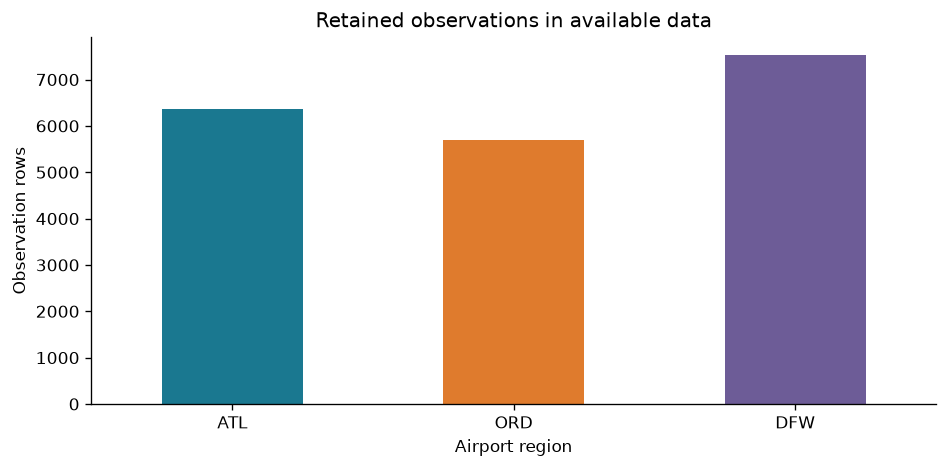

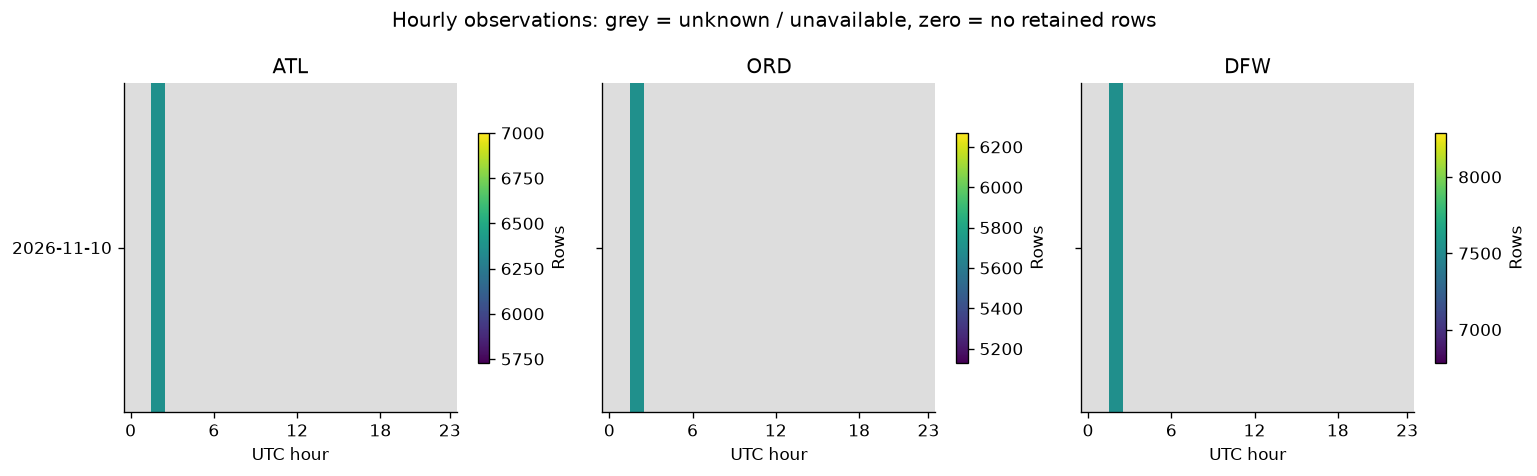

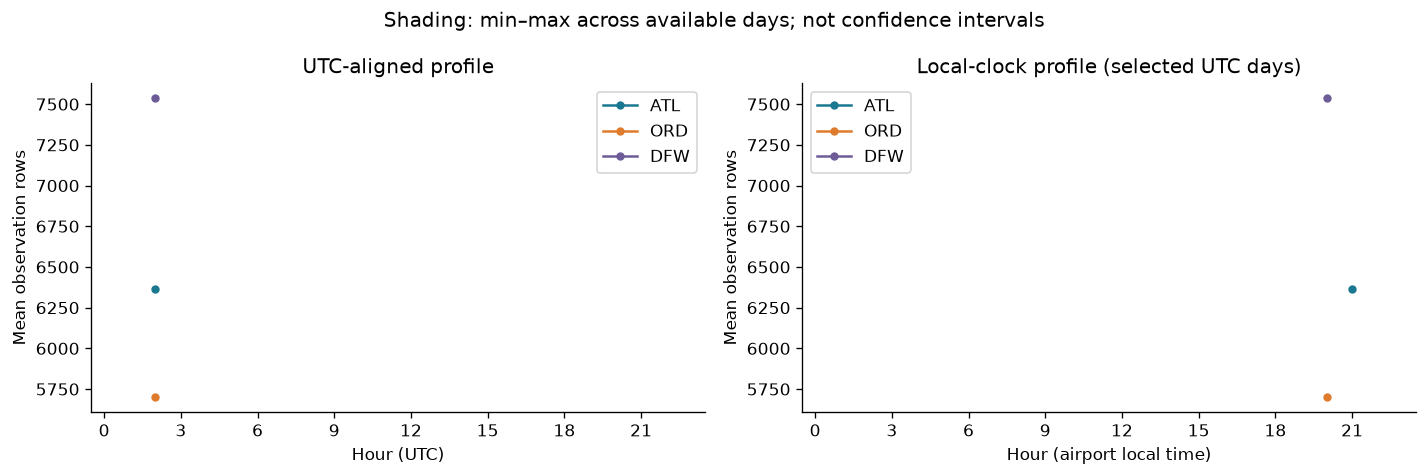

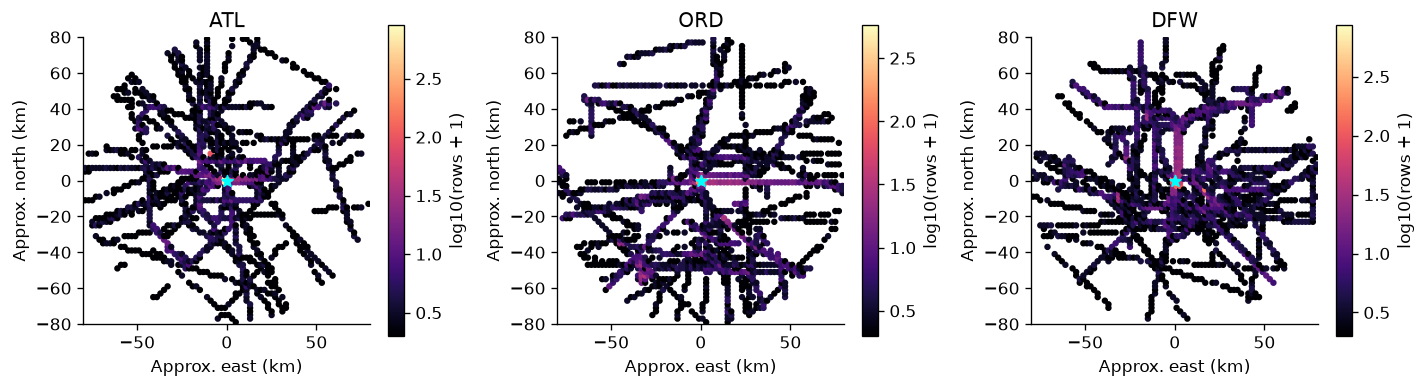

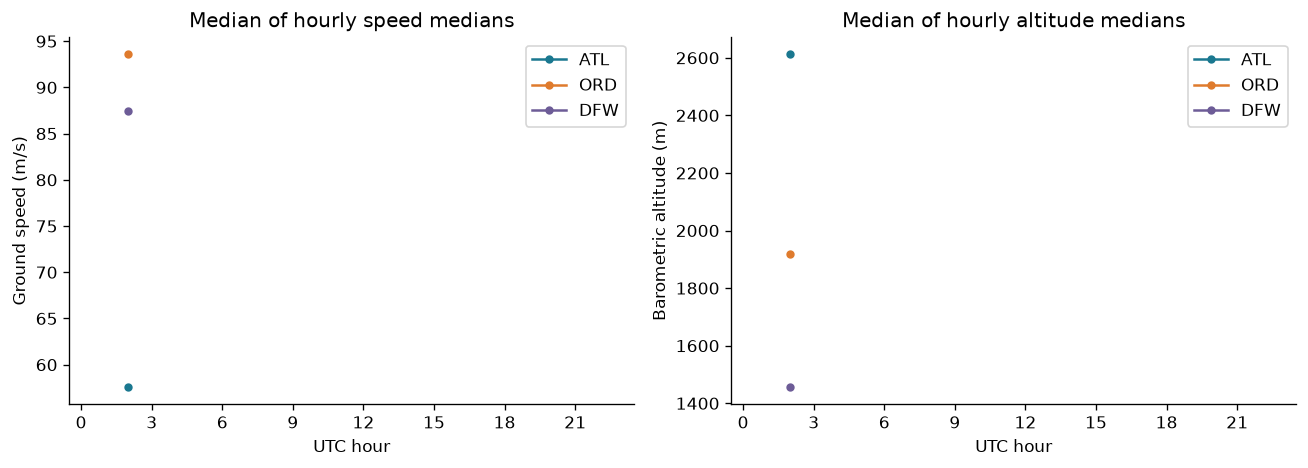

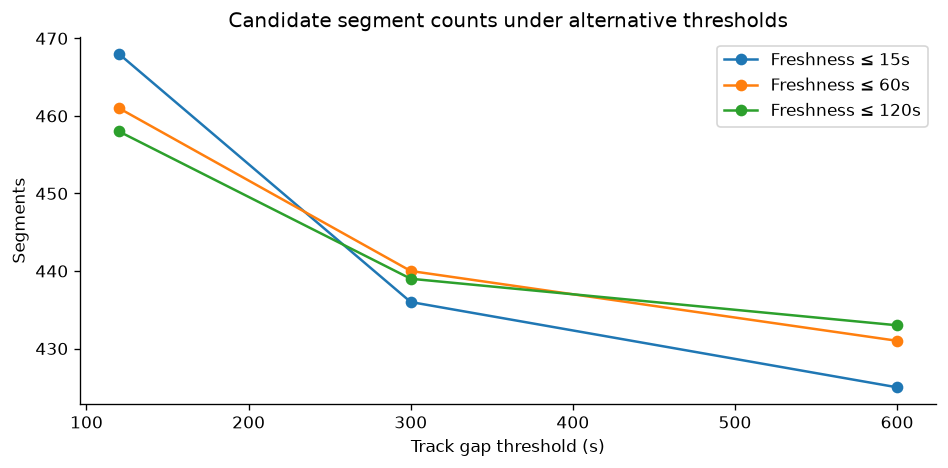

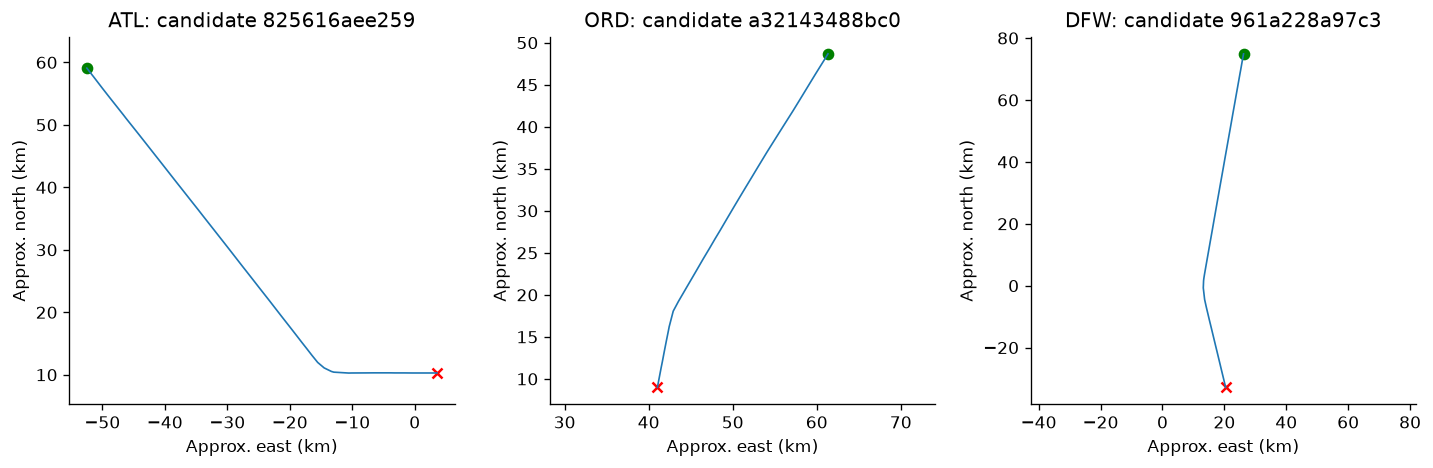

In [16]:
analysis_tables, figure_paths, findings = analyze(results,coverage_table,OUT)
for name in ['region_profile','region_totals','matched_comparison','high_observation_bins','temporal_candidates']:
    if name in analysis_tables:
        display(Markdown('**'+name.replace('_',' ').title()+'**'))
        display(analysis_tables[name].head(15))
for path in figure_paths:
    display(Image(filename=path))


## 6. Validation and sensitivity
Validation checks row accounting, duplicate removal, chronological ordering, maximum within-segment gaps, radial bounds, and segment totals. For every processed region-day, short, middle-length, and long multi-point segments are sampled and traced back to imported rows. This is an automated source-lineage audit; it does not imply that a human has validated flight identities.

Sensitivity varies freshness (**15, 60, 120 s**), segmentation gaps (**120, 300, 600 s**), and speed flags (**250, 350, 450 m/s**). Review whether observation rankings and segment counts change. All changes are descriptive; no causal or statistical significance claim is made.

In [17]:
if not results['validation'].empty:
    display(results['validation'].groupby('check').passed.agg(['count','all']))
    display(results['audits'])
    display(analysis_tables.get('threshold_sensitivity_total',pd.DataFrame()))
    display(results['speed_sensitivity'].groupby('threshold_mps')[['reported_speed_flags','position_jump_flags']].sum())
    assert results['validation'].passed.all(), 'Validation failure: inspect validation.csv.'
    assert results['audits'][['lineage_match','ordered','within_gap_threshold']].all().all(), 'Track audit failure.'
    print('All executed data-integrity and source-lineage checks passed.')
else:
    print('Data-dependent validation has not run: no usable observations.')


,count,all
check,,
deduplicated,3,True
region_bound,3,True
row_accounting,3,True
segment_accounting,3,True
track_gap_limit,3,True
track_ordering,3,True


,day,region,candidate_id,sampled_rows,lineage_match,ordered,within_gap_threshold
0,2026-11-10,ATL,78298cd57ffb,2,True,True,True
1,2026-11-10,ATL,825616aee259,5,True,True,True
2,2026-11-10,ATL,7e40731e43e0,5,True,True,True
3,2026-11-10,DFW,1da5f706ce34,3,True,True,True
4,2026-11-10,DFW,961a228a97c3,5,True,True,True
5,2026-11-10,DFW,09da6c532de9,5,True,True,True
6,2026-11-10,ORD,cf18b64a8269,2,True,True,True
7,2026-11-10,ORD,a32143488bc0,5,True,True,True
8,2026-11-10,ORD,fdb6113dd8bd,5,True,True,True


,stale_seconds,gap_seconds,rows,segments
0,15,120,17516,468
1,15,300,17516,436
2,15,600,17516,425
3,60,120,19604,461
4,60,300,19604,440
5,60,600,19604,431
6,120,120,20805,458
7,120,300,20805,439
8,120,600,20805,433


,reported_speed_flags,position_jump_flags
threshold_mps,,
250,639,594
350,0,1
450,0,1


All executed data-integrity and source-lineage checks passed.


## 7. Findings and conclusions
The statements below are calculated from the actual run. In **archive mode** the planned study is marked complete only when all 96 canonical source hours are acquired, at least 500,000 regional observations remain before and after cleaning, no inputs fail, and validation passes. In **live mode** the status reports how many days and UTC hours were collected and whether validation passed. A live run demonstrates the full pipeline on current data from the same source; it is not the planned four-Monday 2022 study.

**Limits on interpretation:** a few hours or days cannot represent all weekdays or seasons. Missing receivers, stale observations and region boundaries affect activity and segment counts. Partial hours (collection starting or stopping mid-hour) lower that hour's counts; compare `observed_minutes`. Tracks are observational. Official delays and cancellations need an external schedule/status source, which is not part of this analysis.


In [18]:
display(Markdown('**'+status['status']+'**'))
for text in findings:display(Markdown('- '+text))
if DATA_MODE=='archive' and not status['full_four_day_acquisition']:
    print('The full four-day research scope is not complete with these inputs.')
elif DATA_MODE=='live':
    print('Live-data run: results describe the collected window only.')


**LIVE-DATA RUN — VALIDATED (1 day(s), 1 UTC hour(s) with data)**

- Across 1 UTC hour(s) represented on every selected day and in every region, DFW had the highest mean retained observation count per acquired hour (7,537). This is an observation-based comparison, not airport throughput.

- Region profile (retained rows / distinct aircraft-days / median ground speed / median baro altitude): ATL: 6,366 / 126 / 58 m/s / 2,614 m; ORD: 5,701 / 153 / 94 m/s / 1,920 m; DFW: 7,537 / 151 / 87 m/s / 1,455 m. DFW had the most retained observations and ORD the most distinct aircraft in the available data.

- Cleaning retained 19,604 of 23,466 regional rows (83.5%). 0 duplicates and 3,862 stale/future-timestamp rows were excluded.

- 440 candidate within-region segments were reconstructed; 437 contain multiple observations. They do not identify complete flights or scheduled routes.

- 3 observations triggered at least one movement/data-quality flag. 0 hourly count deviations met the exploratory ratio rule. Neither establishes a confirmed disruption.

- The available-data observation-count leader remained DFW across freshness thresholds of 15, 60, and 120 seconds. This sensitivity result does not correct receiver coverage bias.

Live-data run: results describe the collected window only.


## 8. Final report and reproducibility
This cell writes the report, status, provenance, environment versions, validation tables, and results index. All empirical statements come from the current inputs. Source-level records and large partitions remain on your PC. The local project structure is ready to add to your team’s repository; this notebook does not create a remote repository.

References: [The OpenSky Network](https://opensky-network.org), [scientific datasets](https://opensky-network.org/data/scientific), [state-vector documentation](https://openskynetwork.github.io/opensky-api/trino.html), and the team’s project proposal. See Schäfer et al., *Bringing up OpenSky: A large-scale ADS-B sensor network for research* (2014).

In [19]:
def final_report(status,result,tables,findings,out,manifest,failures):
    out=Path(out)
    bullets='\n'.join('- '+x for x in findings)
    if DATA_MODE=='live':
        data_note=(f"Source: OpenSky live REST API polled every 10 s around each airport; {status['hours_with_data']} UTC hour(s) with data. "
                   "The planned 2022 archive (four Mondays) was emptied by OpenSky on 2026-11-04, so this run demonstrates the "
                   "pipeline on current data from the same network and schema.")
    else:
        data_note=f"Verified acquired hourly archives: {status['verified_archive_hours']}/{status['planned_archive_hours']}."
    report=f'''# Reconstructing Aircraft Traffic Patterns from OpenSky Data
Marwan Elawady · Gasser Elkhodary · Amira Alkafoury

## Study status
**{status['status']}**
Data mode: {DATA_MODE}. Dates (UTC): {', '.join(DATES)}. Regions: ATL, ORD, DFW; radius {RADIUS_KM:g} km.
{data_note}
Source rows scanned: {status['source_rows_scanned']:,}; regional rows before cleaning:
{status['regional_rows_before_cleaning']:,}; retained rows: {status['clean_rows']:,}.

## Research question
How do observed aircraft activity, spatial concentration, and movement characteristics vary
between three airport regions and four weekly snapshot days? Which unusual observations
or reporting patterns merit investigation?

## Methods
Read hourly CSV files (live collection) or CSV/gzipped CSV records directly from hourly TAR archives; retain source-file checksums
and row lineage. Standardize Unix seconds to UTC, reject invalid coordinates, and select points
within an approximate 80 km great-circle radius of each airport reference point. Deduplicate
region/aircraft/timestamp keys, keeping the most recent contact timestamp; report conflicting
positions. Retain missing optional measurements; remove known freshness ages above 60 seconds
or below zero. Segment each aircraft's within-region, within-day observations at gaps over
300 seconds; do not split at hourly file boundaries. Aggregate observation counts, distinct
aircraft per hour, movement medians, and approximate 2 km spatial bins. Compare matched acquired
hours; distinguish unknown hours from zero retained observations. Inspect high-speed and position
jump candidates and leave-one-day-out hourly count ratios (only when several days are available).

## Results and conclusions
{bullets}

## Validation
Row accounting, duplicate keys, track ordering, gap limits, radial bounds, and segment totals
are checked for every processed region-day. Representative short, medium, and long segments
are linked to imported source rows. This is an automated lineage audit; a human track review
is not claimed. Sensitivity uses freshness thresholds 15/60/120 seconds, track gaps 120/300/600
seconds, and speed flag thresholds 250/350/450 m/s. See the exported validation and sensitivity tables.

## Limitations
Observation counts measure retained reports, not departures, arrivals, flight counts, or airport
capacity. Receiver coverage, sampling, stale states, missingness, and filtering influence the
results. The collected days do not describe other weekdays or seasons. Region boundaries truncate
trajectories; identifiers can recur across flights. Local-clock comparisons use selected UTC
days, including portions of adjacent local dates. Spatial bins are approximate. Candidate flags
are exploratory and are not confirmed incidents. Three reference Mondays are insufficient for
strong inferential claims about unusual traffic. No official schedule/status dataset was matched,
so cancellations and official delays are outside the evidence. The 2022 source archives were removed
by OpenSky on 2026-11-04, which prevents completion of the planned scope; no data or findings are fabricated to fill them.

## Reproducibility
The notebook writes source_manifest.json, coverage.csv, quality.csv, validation.csv, audits.csv,
threshold and speed sensitivity tables, per-region-day Parquet tracks, figures, and this report.
Review source terms before sharing raw records. Raw source data is fetched or supplied locally,
not embedded in the notebook.

## References
- The OpenSky Network, https://opensky-network.org
- Scientific datasets: https://opensky-network.org/data/scientific
- State-vector schema/units: https://openskynetwork.github.io/opensky-api/trino.html
- Schäfer et al. (2014), Bringing up OpenSky: A large-scale ADS-B sensor network for research.
- Team project proposal, Transportation_Data_Analysis_Project_Proposal.pdf.
'''
    (out/'final_report.md').write_text(report,encoding='utf-8')
    dump(out/'status.json',status);dump(out/'source_manifest.json',manifest);dump(out/'input_failures.json',failures)
    dump(out/'environment.json',{'python':sys.version,'packages':{p:importlib.metadata.version(p) for p in ['pandas','numpy','requests','matplotlib','pyarrow']}})
    return report


In [20]:
report = final_report(status,results,analysis_tables,findings,OUT,manifest,failures)
(ROOT/'reports'/'latest_report.md').write_text(report,encoding='utf-8')
dump(ROOT/'metadata'/'latest_run.json',{'run_id':RUN_ID,'results_path':str(OUT),'status':status['status']})
exports=pd.DataFrame([{'file':p.name,'bytes':p.stat().st_size} for p in sorted(OUT.iterdir()) if p.is_file()])
exports.to_csv(OUT/'results_index.csv',index=False)
display(exports)
print('Report:',OUT/'final_report.md')
print('Study status:',status['status'])


,file,bytes
0,01_region_observations.png,19275
1,02_day_hour_heatmap.png,44688
2,03_temporal_profiles.png,40346
3,04_spatial_density.png,254247
4,05_movement_profiles.png,34606
5,06_sensitivity.png,51913
6,07_sample_track_review.png,67776
7,audits.csv,495
8,config.json,551
9,coverage.csv,6183


Report: c:\Users\gelkhoda\Downloads\aircraft_final\results\20261110T023641574097Z\final_report.md
Study status: LIVE-DATA RUN — VALIDATED (1 day(s), 1 UTC hour(s) with data)
